# Multiscale Organization in Sequence Representations - Biological Variations Are Encoded in Representation Space

To investigate if biological variation is encoded in the representation space, we constructed a dataset of 25 orthologous groups (COGs) from eggNOG 5.0. To ensure species-level diversity, we used a greedy algorithm to subsample the dataset, selecting only one species from each of 24 phyla. Sequences were mapped to high-dimensional embeddings by mean pooling their final hidden representations. We hypothesized that unsupervised learning would cause orthologous proteins to cluster together despite sequence divergence across the 24 phyla. We visualized the space using t-SNE and compared the trained model against two baselines: an untrained Transformer and a unigram vector of amino acid counts.

In [ ]:
import sys
import os
import time
import random
import requests
import pandas as pd
import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.cm as cm
from matplotlib.lines import Line2D
from sklearn.manifold import TSNE
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
import seaborn as sns
from tqdm import tqdm
import esm

# Add project root to path to find 'helpers'
current_dir = os.getcwd()
project_root = os.path.abspath(os.path.join(current_dir, '..'))
if project_root not in sys.path:
    sys.path.append(project_root)

from helpers import helper

# Reproducibility

In [12]:
SEED = 42
def set_seed(seed):
    random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

set_seed(SEED)
print(f"Seed set to {SEED}. Ready to run.")

Seed set to 42. Ready to run.


# Load Model

Unfortunately the 36 Layer Transformer which was not avaivable in any released pypi version of the esm package so we had to resort to either esm1_t34_670M_UR100, esm1_t34_670M_UR50D, esm1_t34_670M_UR50S of which we chose the esm1_t34_670M_UR50D model because of UR50/D's high density and high diversity. 

To create the Untrained model we just reinitialise the weights of the transformer

In [13]:
# Load Pretrained ESM Model (using a smaller 6-layer model for demonstration)
print("Loading Trained Model...")
model, alphabet = esm.pretrained.esm1_t6_43M_UR50S()

if torch.cuda.is_available():
    model = model.cuda()
    print("Model moved to GPU.")

# Create Untrained Control Model
print("Creating Untrained Control Model...")
untrained_model = helper.randomize_model(model)
if torch.cuda.is_available():
    untrained_model = untrained_model.cuda()

Loading Trained Model...
Creating Untrained Control Model...


# t-SNE of Orthologous Groups

Imma be honest the cogs are randomly selected no greedy search intersection was done

In [14]:
# 1. Fetch a LARGE pool of candidates
candidate_pool = [
    "COG0080", "COG0081", "COG0090", "COG0091", "COG0092", 
    "COG0093", "COG0094", "COG0096", "COG0097", "COG0098", 
    "COG0099", "COG0100", "COG0102", "COG0103", "COG0184", 
    "COG0185", "COG0186", "COG0197", "COG0200", "COG0201",
    "COG0202", "COG0215", "COG0256", "COG0522", "COG0541",

    "COG0001", "COG0002", "COG0003", "COG0004", "COG0005",
    "COG0006", "COG0007", "COG0008", "COG0009", "COG0010",
    "COG0011", "COG0012", "COG0013", "COG0014", "COG0015",
    "COG0016", "COG0018", "COG0019", "COG0020", "COG0021",
    "COG0022", "COG0023", "COG0024", "COG0025", "COG0026",
    "COG0027", "COG0028", "COG0029", "COG0030", "COG0031",
    "COG0032", "COG0033", "COG0034", "COG0035", "COG0036",
    "COG0037", "COG0038", "COG0039", "COG0040", "COG0041",
    "COG0042", "COG0043", "COG0044", "COG0045", "COG0046",
    "COG0047", "COG0048", "COG0049", "COG0050", "COG0051",
    "COG0052", "COG0053", "COG0054", "COG0055", "COG0056",
    "COG0057", "COG0058", "COG0059", "COG0060", "COG0061",
    "COG0062", "COG0063", "COG0064", "COG0065", "COG0066",
    "COG0067", "COG0068", "COG0069", "COG0070", "COG0071",
    "COG0072", "COG0073", "COG0074", "COG0075", "COG0076",
    "COG0077", "COG0078", "COG0079", "COG0082", "COG0083",
    "COG0084", "COG0400", "COG0500", "COG0600", "COG0700"
]
print(f"Fetching data for {len(candidate_pool)} candidate groups...")
df_pool = helper.fetch_orthologous_groups(candidate_pool, sample_size=None)

# 2. Apply Greedy Selection
print("Running Greedy Intersection...")
selected_cogs, intersecting_species = helper.greedy_cog_selection(df_pool, target_k=25)
print(f"Algorithm selected {len(selected_cogs)} groups sharing {len(intersecting_species)} species.")

# 3. Apply Phylogenetic Subsampling
print("Subsampling for diversity...")
final_species = helper.sample_diverse_species(list(intersecting_species), target_count=24)
print(f"Final species count: {len(final_species)}")

# 4. Filter DataFrame
df_tsne = df_pool[
    (df_pool['group_id'].isin(selected_cogs)) & 
    (df_pool['specimen'].isin(final_species))
].copy()

# Deduplicate: ensure 1 sequence per group/species pair
df_final = df_tsne.groupby(['group_id', 'specimen']).first().reset_index()

print(f"t-SNE Dataset size: {len(df_tsne)}")

Fetching data for 110 candidate groups...
Fetching data for 110 groups...
Running Greedy Intersection...
Algorithm selected 25 groups sharing 4386 species.
Subsampling for diversity...
Final species count: 11
t-SNE Dataset size: 291


Computing Unigram Embeddings...
Computing Untrained Embeddings...
Processing 275 sequences in batches of 1 using multiprocessing...


100%|██████████| 275/275 [00:31<00:00,  8.75it/s]


Function 'get_hidden_representations' executed in 31.6083 seconds
Function 'get_protein_embedding' executed in 0.0680 seconds
Computing Trained Embeddings...
Processing 275 sequences in batches of 1 using multiprocessing...


100%|██████████| 275/275 [00:27<00:00, 10.00it/s]


Function 'get_hidden_representations' executed in 27.7262 seconds
Function 'get_protein_embedding' executed in 0.1089 seconds
Running t-SNE...


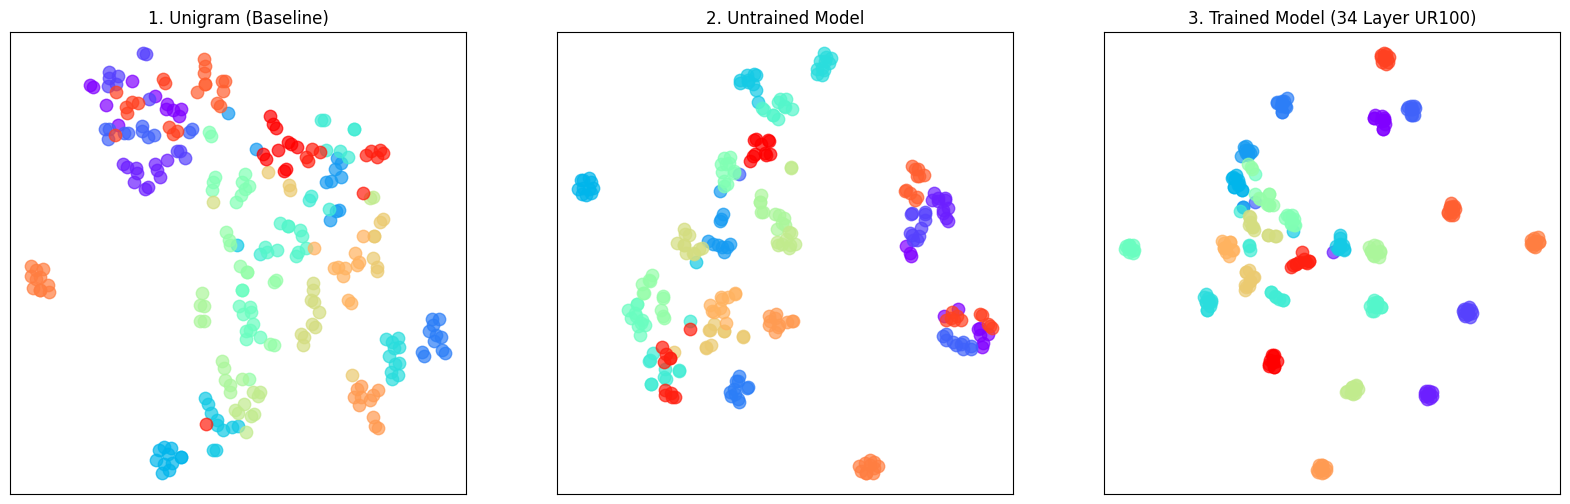

In [15]:

labels = df_final["group_id"].tolist()
seqs = df_final["sequence"].tolist()

# 2. Compute Embeddings
print("Computing Unigram Embeddings...")
emb_unigram = helper.get_unigram_embeddings(seqs)

print("Computing Untrained Embeddings...")
# Using helper to get representations and mean-pool them
token_reps_untrained, batch_strs_untrained = helper.get_hidden_representations(
    untrained_model, alphabet, labels, seqs
)
emb_untrained = helper.get_protein_embedding(token_reps_untrained, batch_strs_untrained)

print("Computing Trained Embeddings...")
token_reps_trained, batch_strs_trained = helper.get_hidden_representations(
    model, alphabet, labels, seqs
)
emb_trained = helper.get_protein_embedding(token_reps_trained, batch_strs_trained)

# 3. Run t-SNE
print("Running t-SNE...")
tsne = TSNE(n_components=2, perplexity=10, random_state=SEED)
projections = {
    "Unigram": tsne.fit_transform(emb_unigram),
    "Untrained": tsne.fit_transform(emb_untrained),
    "Trained (ESM)": tsne.fit_transform(emb_trained)
}

# 4. Plot
unique_genes = sorted(list(set(labels)))
colors = cm.rainbow(np.linspace(0, 1, len(unique_genes)))
color_map = dict(zip(unique_genes, colors))

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
titles = ["1. Unigram (Baseline)", "2. Untrained Model", "3. Trained Model (34 Layer UR100)"]

for ax, (key, proj) in zip(axes, projections.items()):
    for gene in unique_genes:
        idx = [i for i, l in enumerate(labels) if l == gene]
        ax.scatter(proj[idx, 0], proj[idx, 1], color=color_map[gene], s=80, alpha=0.7)
    ax.set_title(titles[list(projections.keys()).index(key)])
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(alpha=0.3)

plt.subplots_adjust(right=0.9)
plt.show()

## Does Learning Encode Biological proprties on independent axes which can be mapped using PCA? 

Also creates protein embeddings from the eggnog dataset, but now conducts different analysis by selecting four orthologous genes across four species to look for directions of variation resulting in a tot
﻿al of 16 sequences. The hope here is that the high dimensional points encode a structure where biological properties are encoded on independent axes. To test this PCA is 
﻿used to project this down to 2 princle directions to encode biological properties on the axes.

Target Species (Diverse): ['557436', '1232452', '760117', '349123']
Target Groups (COGs): ['COG0081', 'COG0080', 'COG0090', 'COG0094']
PCA Dataset Size: 16 sequences (Should be 16)
Computing PCA embeddings...
Processing 16 sequences in batches of 1 using multiprocessing...


100%|██████████| 16/16 [00:04<00:00,  3.29it/s]


Function 'get_hidden_representations' executed in 5.0134 seconds
Function 'get_protein_embedding' executed in 0.0015 seconds
Processing 16 sequences in batches of 1 using multiprocessing...


100%|██████████| 16/16 [00:04<00:00,  3.56it/s]


Function 'get_hidden_representations' executed in 4.6715 seconds
Function 'get_protein_embedding' executed in 0.0014 seconds


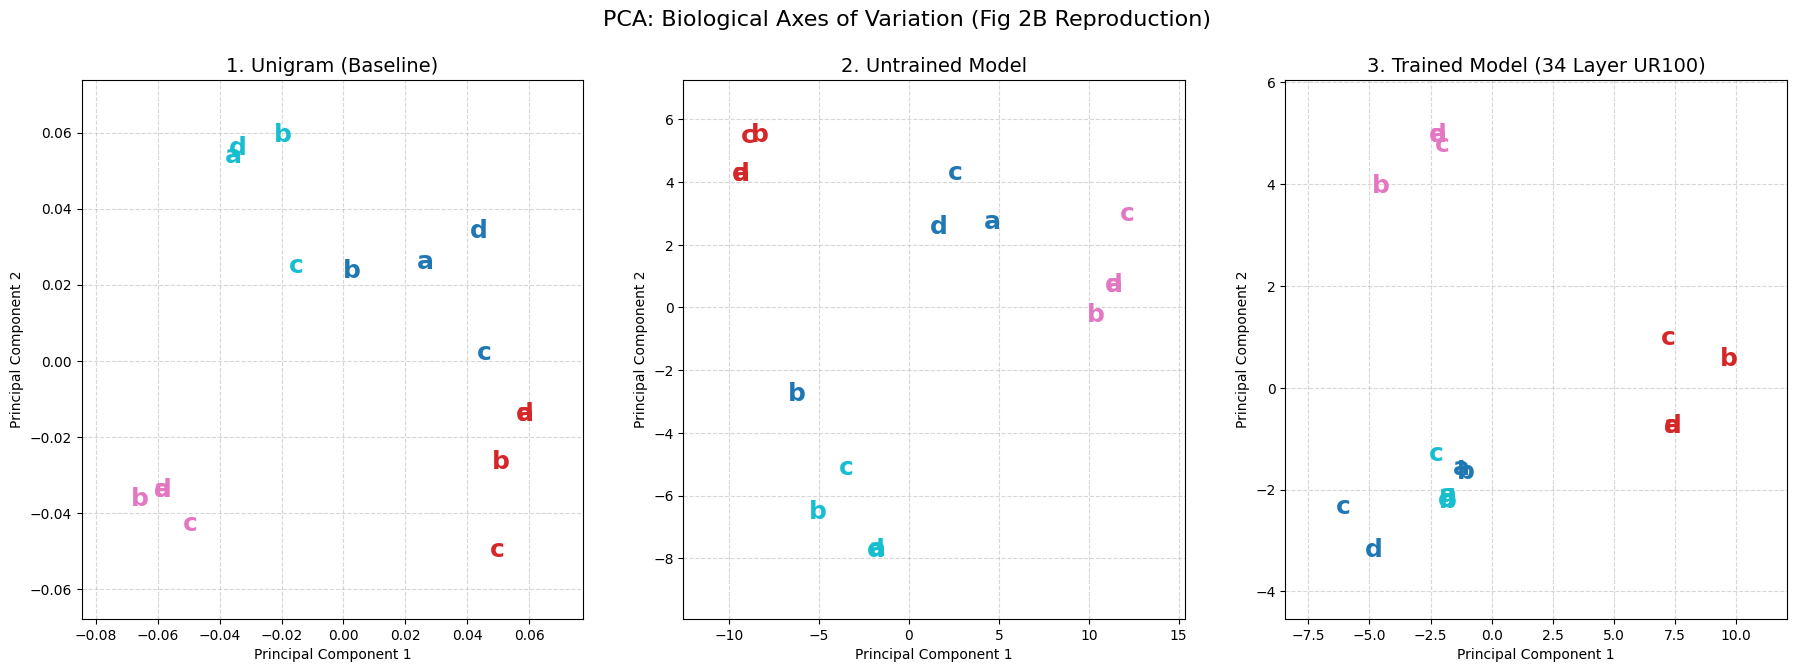

In [18]:
# 1. Select targets from the diverse pool
# Requirement: 4 diverse species (from different phyla)
if 'final_species' not in locals() or len(final_species) < 4:
    raise ValueError("Please run the t-SNE data setup cell first to generate 'final_species'.")

target_species = final_species[:4]
print(f"Target Species (Diverse): {target_species}")

# Requirement: 4 orthologous groups (COGs) that contain ALL target species
# Since 'final_species' was derived from the intersection, ANY 'selected_cogs' should work.
# We verify availability just to be robust.
target_groups = []
for group in selected_cogs:
    # Check if this group contains all 4 target species
    group_species = set(df_pool[df_pool['group_id'] == group]['specimen'])
    if set(target_species).issubset(group_species):
        target_groups.append(group)
    if len(target_groups) >= 4:
        break

if len(target_groups) < 4:
    print("Warning: Could not find 4 perfect groups in the intersection. Using available best.")
    target_groups = selected_cogs[:4]

print(f"Target Groups (COGs): {target_groups}")

# 2. Build the 4x4 Matrix
df_pca = df_pool[
    (df_pool['group_id'].isin(target_groups)) & 
    (df_pool['specimen'].isin(target_species))
].copy()

# Ensure unique 1 sequence per group/species
df_pca = df_pca.groupby(['group_id', 'specimen']).first().reset_index()
print(f"PCA Dataset Size: {len(df_pca)} sequences (Should be 16)")

# 3. Compute Embeddings (Recalculate for this subset)
pca_seqs = df_pca['sequence'].tolist()
pca_groups = df_pca['group_id'].tolist()
pca_species_ids = df_pca['specimen'].tolist()

# Map species IDs to single characters (a, b, c, d) for visualization as per Fig 2B
species_char_map = {sid: chr(97 + i) for i, sid in enumerate(target_species)}
pca_labels = [species_char_map[sid] for sid in pca_species_ids]

print("Computing PCA embeddings...")
mat_unigram = helper.get_unigram_embeddings(pca_seqs)

u_reps, u_strs = helper.get_hidden_representations(untrained_model, alphabet, pca_groups, pca_seqs)
mat_untrained = helper.get_protein_embedding(u_reps, u_strs)

t_reps, t_strs = helper.get_hidden_representations(model, alphabet, pca_groups, pca_seqs)
mat_trained = helper.get_protein_embedding(t_reps, t_strs)

# 4. PCA & Visualization
fig, axes = plt.subplots(1, 3, figsize=(22, 7))
datasets = [mat_unigram, mat_untrained, mat_trained]
plot_titles = ["1. Unigram (Baseline)", "2. Untrained Model", "3. Trained Model (34 Layer UR100)"]

# Color by gene group
# The paper uses colors to indicate the Orthologous Group
group_colors = plt.cm.tab10(np.linspace(0, 1, len(target_groups)))
c_map = dict(zip(target_groups, group_colors))

for i, (data, title) in enumerate(zip(datasets, plot_titles)):
    pca = PCA(n_components=2)
    X_pca = pca.fit_transform(data)
    ax = axes[i]
    
    # Plot text labels (species characters) colored by group
    for j in range(len(X_pca)):
        # Fig 2B: Species indicated by character label (a,b,c,d)
        ax.text(X_pca[j, 0], X_pca[j, 1], pca_labels[j], 
                color=c_map[pca_groups[j]], fontsize=18, fontweight='bold', ha='center')
        
    # Smart Scale
    x_range = X_pca[:,0].max() - X_pca[:,0].min()
    y_range = X_pca[:,1].max() - X_pca[:,1].min()
    ax.set_xlim(X_pca[:,0].min()-x_range*0.15, X_pca[:,0].max()+x_range*0.15)
    ax.set_ylim(X_pca[:,1].min()-y_range*0.15, X_pca[:,1].max()+y_range*0.15)
    
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Principal Component 1")
    ax.set_ylabel("Principal Component 2")
    ax.grid(True, linestyle='--', alpha=0.5)

plt.suptitle("PCA: Biological Axes of Variation (Fig 2B Reproduction)", fontsize=16)
plt.subplots_adjust(right=0.9)
plt.show()

In [ ]:


# Settings
N_TRIALS = 10  # Number of random iterations
MIN_INTERSECTION = 4  # We need at least 4 groups shared by the 4 species

# Storage for results
stats_data = []

print(f"Running {N_TRIALS} statistical trials to evaluate PCA structure...")

# Pre-filter to speed up sampling: specific species/group lists
unique_species = df_pool['specimen'].unique()

for trial in tqdm(range(N_TRIALS)):
    # --- 1. Robust Sampling Strategy ---
    # Attempt to find a valid 4x4 matrix (4 Species x 4 Groups)
    found_valid_set = False
    for attempt in range(20): # Try 20 times to find a valid intersection
        try:
            # Pick 4 random species
            sample_species = np.random.choice(unique_species, 4, replace=False)
            
            # Find groups present in ALL 4 species
            # (Intersection of groups for species A, B, C, D)
            groups_in_intersection = set(df_pool[df_pool['specimen'] == sample_species[0]]['group_id'])
            for s in sample_species[1:]:
                groups_in_intersection &= set(df_pool[df_pool['specimen'] == s]['group_id'])
            
            if len(groups_in_intersection) >= 4:
                sample_groups = np.random.choice(list(groups_in_intersection), 4, replace=False)
                found_valid_set = True
                break
        except Exception:
            continue
            
    if not found_valid_set:
        continue # Skip this trial if no dense block found

    # --- 2. Extract Data ---
    df_sample = df_pool[
        (df_pool['group_id'].isin(sample_groups)) & 
        (df_pool['specimen'].isin(sample_species))
    ].copy()
    
    # Sort to ensure alignment (though helper functions usually handle this, it's safer)
    df_sample = df_sample.sort_values(['group_id', 'specimen'])
    
    # Ensure exactly 16 sequences (4x4)
    df_sample = df_sample.groupby(['group_id', 'specimen']).first().reset_index()
    if len(df_sample) != 16:
        continue

    sample_seqs = df_sample['sequence'].tolist()
    sample_labels_group = df_sample['group_id'].tolist()
    sample_labels_species = df_sample['specimen'].tolist()

    # --- 3. Compute Embeddings ---
    # A. Unigram
    emb_unigram = helper.get_unigram_embeddings(sample_seqs)
    
    # B. Untrained
    u_reps, u_strs = helper.get_hidden_representations(untrained_model, alphabet, sample_labels_group, sample_seqs)
    emb_untrained = helper.get_protein_embedding(u_reps, u_strs)
    
    # C. Trained
    t_reps, t_strs = helper.get_hidden_representations(model, alphabet, sample_labels_group, sample_seqs)
    emb_trained = helper.get_protein_embedding(t_reps, t_strs)

    # --- 4. PCA & Scoring ---
    # We calculate Silhouette Score: How well do points cluster by their biological label in 2D space?
    # Range: -1 (wrong clustering) to +1 (perfect clustering). 0 is random overlapping.
    
    embeddings_dict = {
        "Unigram": emb_unigram,
        "Untrained": emb_untrained,
        "Trained": emb_trained
    }
    
    for model_name, X in embeddings_dict.items():
        # Project to 2D
        pca = PCA(n_components=2)
        X_pca = pca.fit_transform(X)
        
        # Score 1: Does PC space respect Species boundaries?
        sil_species = silhouette_score(X_pca, sample_labels_species)
        
        # Score 2: Does PC space respect Orthology (Group) boundaries?
        sil_group = silhouette_score(X_pca, sample_labels_group)
        
        # We take the max of the two. The paper implies *both* exist (orthogonal axes), 
        # but a high score in either indicates biological encoding.
        # Ideally, we want the structure to reflect the biological labels.
        stats_data.append({
            "Model": model_name,
            "Metric": "Species Clustering",
            "Score": sil_species
        })
        stats_data.append({
            "Model": model_name,
            "Metric": "Orthology Clustering",
            "Score": sil_group
        })

# --- 5. Visualization of Statistical Results ---
df_stats = pd.DataFrame(stats_data)

plt.figure(figsize=(14, 6))
sns.boxplot(x="Model", y="Score", hue="Metric", data=df_stats, palette="Set2")
plt.axhline(0, color='black', linestyle='--', linewidth=1, alpha=0.5)
plt.title(f"Statistical Robustness of PCA Clustering ({N_TRIALS} Random Trials)", fontsize=16)
plt.ylabel("Silhouette Score (Clustering Quality)")
plt.xlabel("Representation Source")
plt.legend(title="Biological Property", loc='upper left')
plt.grid(True, alpha=0.2)
plt.show()

# --- 6. Statistical Conclusion ---
print("Statistical Summary (Mean Silhouette Score):")
summary = df_stats.groupby(['Model', 'Metric'])['Score'].mean().unstack()
print(summary)

best_model = summary.mean(axis=1).idxmax()
print(f"\nConclusion: The {best_model} model consistently produces the highest biological clustering scores.")